# FEG: residual convergence for monotone Lipschitz operators
Let $A$ be monotone and $L$-Lipschitz on a real finite-dimensional Euclidean space, with $L>0$, $R\geq0$, $A(x_\star)=0$ and $\|x_0-x_\star\|^2\leq R^2$. For integer $N\geq1$, measure $\|A(x_N)\|^2$ after the updates
$$x_{k+1/2}=x_k+\frac{x_0-x_k}{k+1}-\frac{k}{(k+1)L}A(x_k),$$
$$x_{k+1}=x_k+\frac{x_0-x_k}{k+1}-\frac{1}{L}A(x_{k+1/2}),\qquad 0\leq k<N.$$
At $k=0$, $x_{1/2}=x_0$ is one shared point and evaluation. The model imposes pairwise monotonicity and Lipschitz inequalities on every evaluated point.


## Proof Statement

### Theorem
Under the assumptions and updates above, for every integer $N\geq1$,
$$\boxed{\|A(x_{N})\|^2\leq\frac{4L^2R^2}{N^2}.}$$
A certificate is the potential $V_{0}=0$ and
$$\boxed{V_{k}=\frac{2k^2}{N^2}\|A(x_{k})\|^2+\frac{4Lk}{N^2}\langle A(x_{k}),x_{k}-x_{0}\rangle,\qquad 1\leq k\leq N.}$$
This potential is nonincreasing. It need not be nonnegative; the terminal identity below is what converts $V_{N}\leq0$ into the residual bound. The result includes $R=0$ and $N=1$.


### Proof outline
Define the nonpositive residuals
$$\mathcal L_{j}=\|A(x_{j})-A(x_{j-1/2})\|^2-L^2\|x_{j}-x_{j-1/2}\|^2,\qquad 1\leq j\leq N,$$
$$\mathcal M_{k}=-\langle A(x_{k+1})-A(x_{k}),x_{k+1}-x_{k}\rangle,\qquad 1\leq k<N,$$
$$\mathcal M_{\star}=-\langle A(x_{N}),x_{N}-x_{\star}\rangle,\qquad
\mathcal I_{0}=\|x_{0}-x_{\star}\|^2-R^2.$$
Lipschitz continuity, monotonicity, the zero-point assumption and the initial condition give $\mathcal L_j,\mathcal M_k,\mathcal M_\star,\mathcal I_0\leq0$.

For $V_{k}=2k^2\|A(x_k)\|^2/N^2+4Lk\langle A(x_k),x_k-x_0\rangle/N^2$, the shared initial point $x_{1/2}=x_0$ gives
$$V_{1}-V_{0}=\frac{2}{N^2}\mathcal L_{1}\leq0.$$
Substituting the two update equations yields the exact identity
$$V_{k+1}-V_{k}=\frac{2(k+1)^2}{N^2}\mathcal L_{k+1}+\frac{4Lk(k+1)}{N^2}\mathcal M_{k}\leq0,\qquad 1\leq k<N.$$
Both coefficients are nonnegative, hence $V_N\leq\cdots\leq V_1\leq V_0=0$. Let
$$\mathcal S_N=\left\|A(x_N)-\frac{2L}{N}(x_0-x_\star)\right\|^2\geq0.$$
The exact terminal identity is
$$\|A(x_N)\|^2-\frac{4L^2R^2}{N^2}
=V_N+\frac{4L}{N}\mathcal M_\star+\frac{4L^2}{N^2}\mathcal I_0-\mathcal S_N\leq0.$$
This proves the claim. For $N=1$, the interior sum is empty and the same base and terminal identities apply. No division by $R$ or by $\|A(x_N)\|$ is used, so zero-radius and zero-residual cases are included.


In [1]:
from pathlib import Path
import sys

notebook_dir = Path.cwd().resolve()
repo_root = notebook_dir / "supplementary" / "approved"
sys.path[:0] = [str(repo_root), str(notebook_dir / "supplementary" / "helpers")]

In [2]:
import runtime  # ty: ignore[unresolved-import]  # Notebook bootstrap adds the helper directory to sys.path.
import json
import pepflow as pf
import sympy as sp
import matplotlib.pyplot as plt

print("Framework:", pf.__file__, "Approved root:", runtime.APPROVED)

Framework: C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\feg\r04\supplementary\approved\pepflow\__init__.py Approved root: C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\feg\r04\supplementary\approved


In [3]:
L = pf.Parameter("L")
R = pf.Parameter("R")
A = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A"], L=L)

In [4]:
def make_ctx_feg(ctx_name: str, N, **kwargs) -> pf.PEPContext:
    """Encode the supplied recurrence, sharing x_0 and x_{1/2}."""
    ctx = pf.PEPContext(ctx_name).set_as_current()
    x0 = pf.Vector(is_basis=True, tags=["x_0"])
    A.set_zero_point("x_star")
    x = x0
    for k in range(int(N)):
        t = sp.Integer(k + 1)
        if k == 0:
            half = x0
            half.add_tag("x_1/2")
        else:
            half = x + (x0 - x) / t - sp.Integer(k) / (t * L) * A(x)
            half.add_tag(f"x_{2 * k + 1}/2")
        x = x + (x0 - x) / t - A(half) / L
        x.add_tag(f"x_{k + 1}")
    A(x)
    return ctx


def get_pep_setup(N, params):
    """Return context, builder, and operator for the numerical PEP."""
    ctx = make_ctx_feg(f"ctx_{N}", N)
    pb = pf.PEPBuilder(ctx)
    pb.add_initial_constraint(
        ((ctx["x_0"] - ctx["x_star"]) ** 2).le(R**2, name="initial_condition")
    )
    pb.set_performance_metric(A(ctx[f"x_{N}"]) ** 2)
    return ctx, pb, A

## Numerical evidence
CLARABEL with default options, $L=R=1$. The saved sweep was produced from the displayed setup; it is reused here without repeating solves. These SDP values support a conjecture, not an arbitrary-horizon proof.

N=1: PEP=1.9999999956; candidate=4.0000000000; status=optimal
N=2: PEP=0.9999999960; candidate=1.0000000000; status=optimal
N=3: PEP=0.4444444508; candidate=0.4444444444; status=optimal
N=4: PEP=0.2500000070; candidate=0.2500000000; status=optimal
N=5: PEP=0.1600000044; candidate=0.1600000000; status=optimal
N=6: PEP=0.1111111199; candidate=0.1111111111; status=optimal
N=7: PEP=0.0816326585; candidate=0.0816326531; status=optimal


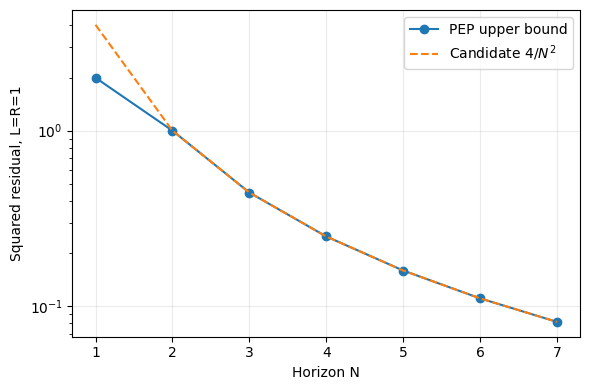

Max candidate discrepancy for N>=2: 8.768797521430116e-09
Initial half-step alias verified: True


In [5]:
sweep = json.loads((notebook_dir / "state" / "feg_b1.json").read_text())[
    "sweep_results"
]
for row in sweep:
    print(
        f"N={row['N']}: PEP={row['opt_value']:.10f}; candidate={4 / row['N'] ** 2:.10f}; status={row['status']}"
    )
ns = [row["N"] for row in sweep]
values = [row["opt_value"] for row in sweep]
plt.figure(figsize=(6, 4))
plt.plot(ns, values, "o-", label="PEP upper bound")
plt.plot(ns, [4 / n**2 for n in ns], "--", label=r"Candidate $4/N^2$")
plt.yscale("log")
plt.xlabel("Horizon N")
plt.ylabel("Squared residual, L=R=1")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print(
    "Max candidate discrepancy for N>=2:",
    max(abs(row["opt_value"] - 4 / row["N"] ** 2) for row in sweep[1:]),
)
print(
    "Initial half-step alias verified:", all(row["initial_half_is_x0"] for row in sweep)
)

For $N\geq2$, the observed values agree with $4/N^2$ to numerical solver precision. At $N=1$, the SDP gives $2$, so the uniform candidate is loose there. Scaling the variables by $R$ and the operator by $L$ gives the candidate $4L^2R^2/N^2$; the zero-radius case is stationary. No analytic proof is claimed in Block 1.



## Dense and relaxed proof solves
At $N=6$, retain the monotonicity pairs $(x_k,x_{k+1})$, $1\leq k<N$, and $(x_N,x_\star)$, plus the Lipschitz pairs $(x_j,x_{j-1/2})$, $1\leq j\leq N$. The trial drops dense multipliers smaller than $10^{-6}$ and obtains a fresh coherent primal certificate. All displayed numerical components belong to that selected solve.

In [6]:
import numpy as np
import hashlib
from pepflow.utils import Comparator
from certificate import digest  # ty: ignore[unresolved-import]  # Notebook bootstrap adds the helper directory to sys.path.

dense = json.loads((notebook_dir / "state/feg_dense.json").read_text())
b2 = json.loads((notebook_dir / "state/feg_b2.json").read_text())
assert b2["certificate_id"] == digest(b2)
for relative, expected in b2["certificate_provenance"]["source_hashes"].items():
    assert (
        hashlib.sha256((notebook_dir / relative).read_bytes()).hexdigest() == expected
    )
print("Dense:", dense["opt_value"], "Selected:", b2["opt_value"])
print("Gap:", abs(dense["opt_value"] - b2["opt_value"]))
print("Basis:", b2["basis_vectors"])
print("Dense S eigenvalues:", np.linalg.eigvalsh(dense["S_matrix"]))
for group in dense["lambda_groups"]:
    active = [
        (name, value)
        for name, value in dense["named_dual_values"].items()
        if dense["constraint_metadata"][name]["group"] == group
        and value is not None
        and abs(value) > 1e-6
    ]
    print("Dense significant group", group, active)
print("Dropped constraints:", len(b2["relaxed_constraints"]))
for name, value in b2["named_dual_values"].items():
    if value is not None:
        print(name, value)
assert abs(dense["opt_value"] - b2["opt_value"]) < 1e-5

Dense: 0.11111111987990863 Selected: 0.11111111913421273
Gap: 7.456958939222602e-10
Basis: ['x_1/2', 'x_star', 'A(x_1/2)', 'A(x_1)', 'A(x_3/2)', 'A(x_2)', 'A(x_5/2)', 'A(x_3)', 'A(x_7/2)', 'A(x_4)', 'A(x_9/2)', 'A(x_5)', 'A(x_11/2)', 'A(x_6)']
Dense S eigenvalues: [8.39304756e-11 3.12048781e-10 1.29506407e-09 1.48441681e-09
 3.74262832e-09 7.48945764e-09 1.01712954e-08 1.98971038e-08
 2.28208708e-08 2.54735547e-08 2.89888755e-08 3.77429634e-08
 5.92976632e-08 1.22214889e+00]
Dense significant group Monotone Operator Inequality [('A monotone:x_1,x_2', 0.22221407582035477), ('A monotone:x_2,x_3', 0.6666422281011879), ('A monotone:x_3,x_4', 1.3332844303843185), ('A monotone:x_4,x_5', 2.2221406732067917), ('A monotone:x_5,x_6', 3.333210972556232), ('A monotone:x_6,x_star', 0.66664221028909)]
Dense significant group Lipschitz Continuous Inequality [('A Lipschitz:x_1,x_1/2', 0.05555352252423431), ('A Lipschitz:x_2,x_3/2', 0.22221408980181306), ('A Lipschitz:x_3,x_5/2', 0.4999816844903659), (

## Lambda and S verification
The numerical identity uses each inequality residual $r_c\leq0$ and the same solve's Gram remainder:
$$\|A(x_N)\|^2-\mathrm{bound}-\sum_c\lambda_c r_c+S=0.$$
The initial residual includes its constant $-R^2$. Thus nonnegative multipliers and $S\succeq0$ imply the bound. All Gram, scalar-value and offset coordinates are checked. The numerical LDL decomposition retains every factor, including small terms and any off-diagonal blocks; no small term is silently discarded.


In [7]:
PARAMS: dict[str, pf.NUMERICAL_TYPE] = {"L": sp.S.One, "R": sp.S.One}


def inventory(ctx, pb, op):
    entries = [(c, "initial", None, None) for c in pb.init_conditions]
    groups = ctx.get_constraint_data(op)
    entries += [
        (c, "interpolation", str(op), str(group))
        for group, cs in groups.sc_dict.items()
        for c in cs
    ]
    assert (
        not groups.psd_dict
        and len(ctx.oper_to_duplets) == 1
        and not ctx.func_to_triplets
    )
    return entries


def verify(data, ctx=None, pb=None, op=None, dense_value=None):
    if ctx is None:
        ctx, pb, op = get_pep_setup(data["N_verify"], PARAMS)
    assert pb is not None and op is not None
    ctx.set_as_current()
    entries = inventory(ctx, pb, op)
    assert set(data["constraint_metadata"]) == {c.name for c, *_ in entries}
    assert set(data["named_dual_values"]) == set(data["constraint_metadata"])
    assert data["basis_vectors"] == [str(v) for v in ctx.basis_vectors()]
    pm = pf.ExpressionManager(ctx, resolve_parameters=PARAMS)
    weighted = pf.Scalar.zero()
    ineq = []
    for c, *_ in entries:
        val = data["named_dual_values"][c.name]
        if data["constraint_metadata"][c.name]["relaxed"]:
            assert val is None
            continue
        assert val is not None and np.isfinite(val)
        residual = c.lhs - c.rhs
        if c.cmp in (Comparator.GE, Comparator.SEQ):
            residual = -residual
        weighted += float(val) * (pf.Scalar.zero() + residual)
        if c.cmp != Comparator.EQ:
            ineq.append(float(val))
    E = np.asarray(data["numerical_decomposition"]["ell_coords"])
    D = np.asarray(data["numerical_decomposition"]["D"])
    S = np.asarray(data["S_matrix"])
    basis = ctx.basis_vectors()
    ell = [
        sum((float(a) * v for a, v in zip(row, basis)), pf.Vector.zero()) for row in E
    ]
    square = sum(
        (float(D[i, j]) * ell[i] * ell[j] for i, j in np.ndindex(D.shape)),
        pf.Scalar.zero(),
    )
    checked = pm.eval_scalar(
        pb.performance_metric - float(data["opt_value"]) - weighted + square
    )

    def maxabs(x):
        return float(np.max(np.abs(np.asarray(x, dtype=float)), initial=0))

    tol = dict(
        identity_atol=1e-5,
        identity_rtol=0.0,
        reconstruction_atol=1e-4,
        reconstruction_rtol=1e-5,
        dual_tol=1e-6,
        psd_tol=1e-6,
        dense_opt_atol=1e-5,
    )
    res = dict(
        identity_gram_max_abs=maxabs(checked.inner_prod_coords),
        identity_func_max_abs=maxabs(checked.func_coords),
        identity_offset_abs=maxabs(checked.offset),
        S_reconstruction_max_abs=maxabs(E.T @ D @ E - S),
        dense_relaxed_gap=abs(
            data["opt_value"]
            - (data["opt_value"] if dense_value is None else dense_value)
        ),
        minimum_scalar_inequality_dual=min(ineq, default=0),
        minimum_S_eigenvalue=float(np.linalg.eigvalsh((S + S.T) / 2).min()),
        minimum_matrix_inequality_eigenvalue=0.0,
    )
    passed = (
        data["certificate_provenance"]["solver_status"] == "optimal"
        and all(
            res[k] <= tol["identity_atol"]
            for k in (
                "identity_gram_max_abs",
                "identity_func_max_abs",
                "identity_offset_abs",
            )
        )
        and np.allclose(
            E.T @ D @ E,
            S,
            atol=tol["reconstruction_atol"],
            rtol=tol["reconstruction_rtol"],
        )
        and res["dense_relaxed_gap"] < tol["dense_opt_atol"]
        and res["minimum_scalar_inequality_dual"] >= -tol["dual_tol"]
        and res["minimum_S_eigenvalue"] >= -tol["psd_tol"]
        and np.allclose(S, S.T, atol=tol["psd_tol"], rtol=0)
    )
    return dict(tolerances=tol, residuals=res, passed=bool(passed))


checks = verify(b2, dense_value=dense["opt_value"])
print(checks)
assert checks["passed"]

{'tolerances': {'identity_atol': 1e-05, 'identity_rtol': 0.0, 'reconstruction_atol': 0.0001, 'reconstruction_rtol': 1e-05, 'dual_tol': 1e-06, 'psd_tol': 1e-06, 'dense_opt_atol': 1e-05}, 'residuals': {'identity_gram_max_abs': 7.512999260122765e-09, 'identity_func_max_abs': 0.0, 'identity_offset_abs': 6.564890756011188e-09, 'S_reconstruction_max_abs': 5.551115123125783e-17, 'dense_relaxed_gap': 7.456958939222602e-10, 'minimum_scalar_inequality_dual': 0.05556830706343723, 'minimum_S_eigenvalue': 7.343470692425838e-10, 'minimum_matrix_inequality_eigenvalue': 0.0}, 'passed': True}


In [8]:
E = np.asarray(b2["numerical_decomposition"]["ell_coords"])
D = np.asarray(b2["numerical_decomposition"]["D"])
S_saved = np.asarray(b2["S_matrix"])
pf.pprint_labeled_matrix(
    pf.MatrixWithNames(S_saved, b2["basis_vectors"], b2["basis_vectors"])
)
print("LDL diagonal:", np.diag(D))
print("Minimum eigenvalue of D:", np.linalg.eigvalsh(D).min())
pf.pprint_labeled_matrix(
    pf.MatrixWithNames(E, [f"ell_{i}" for i in range(len(E))], b2["basis_vectors"])
)
pf.pprint_labeled_matrix(
    pf.MatrixWithNames(E.T @ D @ E - S_saved, b2["basis_vectors"], b2["basis_vectors"])
)
assert np.allclose(E.T @ D @ E, S_saved, atol=1e-4, rtol=1e-5)

<IPython.core.display.Math object>

LDL diagonal: [1.00045833e+00 7.51153006e-09 2.76501551e-08 7.48731479e-09
 3.51615286e-08 6.59481809e-09 2.70457645e-08 5.40293328e-09
 1.88429287e-08 4.96182345e-09 1.18374812e-08 2.26313258e-09
 9.84068699e-09 9.28986423e-09]
Minimum eigenvalue of D: 2.263132583329161e-09


<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Initial closed-form search
The active multipliers suggest
$$\lambda^{\rm mon}_{k,k+1}=\frac{4Lk(k+1)}{N^2},\quad\lambda^{\rm mon}_{N,\star}=\frac{4L}{N},\quad\lambda^{\rm Lip}_{j,j-1/2}=\frac{2j^2}{N^2},\quad\tau=\frac{4L^2}{N^2}.$$
The rank-one remainder suggests
$$S_{\rm candidate}=\left\|A(x_N)-\frac{2L}{N}(x_0-x_\star)\right\|^2.$$
These candidates satisfy the exact coordinate identity at $N=6$, $L=R=1$. They do **not** match every selected numerical coefficient within $10^{-4}$: the finite numerical dual has small perturbations amplified along its nearly singular optimum. Therefore the complete numerical certificate, rather than rounded candidates, is carried forward. The arbitrary-horizon identity remains unresolved here; the numerical check is not an analytic theorem.


In [9]:
def candidate_lambda(name, N, L=sp.S.One):
    N = sp.S(N)
    if name == "initial_condition":
        return 4 * L**2 / N**2
    family, pair = name.split(":")
    p, q = pair.split(",")
    points = {p, q}
    if family == "A monotone":
        if points == {f"x_{N}", "x_star"}:
            return 4 * L / N
        for k in range(1, int(N)):
            if points == {f"x_{k}", f"x_{k + 1}"}:
                return 4 * L * k * (k + 1) / N**2
    if family == "A Lipschitz":
        for j in range(1, int(N) + 1):
            if points == {f"x_{j}", f"x_{2 * j - 1}/2"}:
                return 2 * sp.Integer(j) ** 2 / N**2
    return sp.S.Zero


def candidate_S(ctx, A, N, L=sp.S.One):
    return (A(ctx[f"x_{N}"]) - 2 * L / sp.S(N) * (ctx["x_0"] - ctx["x_star"])) ** 2

In [10]:
ctx, pb, A = get_pep_setup(6, PARAMS)
pm = pf.ExpressionManager(ctx, resolve_parameters=PARAMS)
entries = inventory(ctx, pb, A)
weighted = sum(
    (candidate_lambda(c.name, 6) * (c.lhs - c.rhs) for c, *_ in entries),
    pf.Scalar.zero(),
)
S_guess = candidate_S(ctx, A, 6)
exact = pm.eval_scalar(
    pb.performance_metric - sp.Rational(4, 36) - weighted + S_guess, sympy_mode=True
)
exact_checks = {
    name: all(
        sp.simplify(v) == 0 for v in np.asarray(getattr(exact, name), dtype=object).flat
    )
    for name in ("inner_prod_coords", "func_coords", "offset")
}
for group, matrix_data in b2["lambda_groups"].items():
    family = "A monotone" if group == "Monotone Operator Inequality" else "A Lipschitz"
    candidate_matrix = np.array(
        [
            [
                candidate_lambda(f"{family}:{ri},{ci}", 6)
                for ci in matrix_data["col_names"]
            ]
            for ri in matrix_data["row_names"]
        ],
        dtype=object,
    )
    pf.pprint_labeled_matrix(
        pf.MatrixWithNames(
            candidate_matrix, matrix_data["row_names"], matrix_data["col_names"]
        )
    )
print("Exact sample coordinate checks:", exact_checks)
assert all(exact_checks.values())
pf.pprint_labeled_matrix(
    pf.MatrixWithNames(
        np.asarray(exact.inner_prod_coords), b2["basis_vectors"], b2["basis_vectors"]
    )
)
lambda_error = max(
    abs(float(candidate_lambda(name, 6)) - value)
    for name, value in b2["named_dual_values"].items()
    if value is not None
)
S_candidate_array = np.asarray(pm.eval_scalar(S_guess).inner_prod_coords, dtype=float)
S_error = np.max(np.abs(S_candidate_array - S_saved))
pf.pprint_labeled_matrix(
    pf.MatrixWithNames(S_candidate_array, b2["basis_vectors"], b2["basis_vectors"])
)
print("Candidate lambda mismatch:", lambda_error, "S mismatch:", S_error)
print("Initial search record:", b2["closed_form_search"])
print("Numerical certificate verified:", checks["passed"])
print("Analytic full-PEP verified:", b2["analytic_full_pep_verified"])
print("Lyapunov proof verified:", b2["lyapunov_proof_verified"])

C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\feg\r04\supplementary\approved\pepflow\pep_context.py:172: UserWarning:

The provided name was already used. The older PEPContext will be overwritten. PEPBuilders constructed with the older PEPContext should be remade.



<IPython.core.display.Math object>

<IPython.core.display.Math object>

Exact sample coordinate checks: {'inner_prod_coords': True, 'func_coords': True, 'offset': True}


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Candidate lambda mismatch: 0.0007638794501909629 S mismatch: 0.0004583265227982025
Initial search record: {'completed': True, 'references_reviewed': [], 'reference_scope_note': 'No pre-existing case references authorized; candidates derived from this attempt dense and sparse data.', 'attempts': [{'method': 'Inspect support, rational approximations and index-scaled multipliers', 'outcome': 'Candidate monotone 4*L*k*(k+1)/N**2, final-star 4*L/N; Lipschitz 2*j**2/N**2; tau 4*L**2/N**2', 'matching_atol': 0.0001, 'max_error': 0.0007638794501909629, 'matching_passed': False}, {'method': 'Inspect rank-one S and complete the final residual square', 'outcome': 'Candidate ||A(x_N)-2L/N*(x0-xstar)||**2', 'matching_atol': 0.0001, 'max_error': 0.0004583265227982025, 'matching_passed': False}, {'method': 'Exact symbolic full-coordinate identity at N=6, L=R=1', 'checks': {'inner_prod_coords': True, 'func_coords': True, 'offset': True}, 'outcome': 'Exact finite-horizon identity holds; not an arbitrary

## Partial-sum Lyapunov construction
Write $r^{\rm Lip}_j=\|A(x_j)-A(x_{j-1/2})\|^2-L^2\|x_j-x_{j-1/2}\|^2\leq0$ and $r^{\rm mon}_k=-\langle A(x_{k+1})-A(x_k),x_{k+1}-x_k\rangle\leq0$. Using the selected numerical multipliers, set $V_0=0$ and
$$V_{k+1}-V_k=\lambda^{\rm Lip}_{k+1}r^{\rm Lip}_{k+1}+\mathbf{1}_{k\geq1}\lambda^{\rm mon}_{k}r^{\rm mon}_{k}.$$
The multipliers are nonnegative, so this convention gives $V_{k+1}\leq V_k$. Keep the single final zero-point monotonicity residual and the entire positive-semidefinite $S$ block for the boundary argument. No interpolation or square term is omitted.

The same recipe gives interior rank two at $N=4$ and $N=6$, excluding only $V_0,V_N$. The rank uses absolute singular values with threshold $10^{-4}$ in the setup's coordinate order. Coverage is checked in Gram, function-value and constant coordinates. This remains finite-sample structure discovery, not an arbitrary-horizon proof.


In [11]:
import hashlib
import json
from pathlib import Path
import numpy as np
import pepflow as pf
import sympy as sp

notebook_dir = Path.cwd().resolve()
certificate = json.loads((notebook_dir / "state/feg_b2.json").read_text())
N_int = certificate["N_verify"]
params_sp: dict[str, pf.NUMERICAL_TYPE] = {"L": sp.S.One, "R": sp.S.One}
assert json.loads(certificate["params_json"]) == {"L": 1, "R": 1}
assert certificate["certificate_id"] == digest(certificate)
assert certificate["closed_form_search"]["completed"]
for relative, expected in certificate["certificate_provenance"][
    "source_hashes"
].items():
    assert (
        hashlib.sha256((notebook_dir / relative).read_bytes()).hexdigest() == expected
    )
assert (
    Path(pf.__file__).resolve()
    == notebook_dir / "supplementary/approved/pepflow/__init__.py"
)
ctx, pb, obj = get_pep_setup(N_int, params_sp)
pb.set_relaxed_constraints(certificate["relaxed_constraints"])
pm = pf.ExpressionManager(ctx, resolve_parameters=params_sp)
records = inventory(ctx, pb, obj)
basis = ctx.basis_vectors()
basis_labels = [str(v) for v in basis]
assert (
    basis_labels
    == certificate["basis_vectors"]
    == certificate["S_row_names"]
    == certificate["S_col_names"]
)
assert [str(v) for v in ctx.basis_scalars()] == certificate["basis_scalars"]
assert set(certificate["named_dual_values"]) == {c.name for c, *_ in records}
weighted_terms, interpolation_terms, extra_terms, extra_duals = {}, {}, {}, {}
for c, origin, owner, group in records:
    assert isinstance(c, pf.ScalarConstraint)
    expected = dict(
        origin=origin,
        owner=owner,
        group=group,
        kind="scalar",
        comparator=c.cmp.value,
        shape=[],
        relaxed=c.name in pb.relaxed_constraints,
    )
    assert certificate["constraint_metadata"][c.name] == expected
    val = certificate["named_dual_values"][c.name]
    if expected["relaxed"]:
        assert val is None
        continue
    assert val is not None and np.isfinite(val) and val >= -1e-6
    assert c.cmp.name == "LE"
    term = float(val) * (c.lhs - c.rhs)
    weighted_terms[c.name] = term
    if origin == "interpolation":
        interpolation_terms[c.name] = term
    elif c.name != certificate["tau_name"]:
        extra_terms[c.name] = term
        extra_duals[c.name] = val
assert not extra_terms
assert (
    certificate["tau_name"]
    == certificate["normalization"]["tau_name"]
    == "initial_condition"
)
assert certificate["tau_sol"] == certificate["named_dual_values"]["initial_condition"]
assert certificate["normalization"]["bound_value"] == certificate["opt_value"]
certificate_checks = verify(certificate, ctx, pb, obj)
assert certificate_checks["passed"]
certificate_checked = True
S_array = np.asarray(certificate["S_matrix"])
S_scalar = sum(
    (float(S_array[i, j]) * basis[i] * basis[j] for i, j in np.ndindex(S_array.shape)),
    pf.Scalar.zero(),
)
tol = certificate_checks["tolerances"]
print("Certificate reconstructed and checked:", certificate_checks["residuals"])

Certificate reconstructed and checked: {'identity_gram_max_abs': 7.512999260122765e-09, 'identity_func_max_abs': 0.0, 'identity_offset_abs': 6.564890756011188e-09, 'S_reconstruction_max_abs': 5.551115123125783e-17, 'dense_relaxed_gap': 0.0, 'minimum_scalar_inequality_dual': 0.05556830706343723, 'minimum_S_eigenvalue': 7.343470692425838e-10, 'minimum_matrix_inequality_eigenvalue': 0.0}


In [12]:
# The candidate rank-one square failed the B2 comparison tolerance. Retain the
# entire saved S as one PSD boundary block, reconstructed from all LDL factors.
D = np.asarray(certificate["numerical_decomposition"]["D"])
E = np.asarray(certificate["numerical_decomposition"]["ell_coords"])
assert certificate["numerical_decomposition"]["basis_labels"] == basis_labels
assert np.allclose(E.T @ D @ E, S_array, atol=1e-4, rtol=1e-5)
ell = [sum((float(a) * v for a, v in zip(row, basis)), pf.Vector.zero()) for row in E]
S_piece_terms = {
    "whole_S": sum(
        (float(D[i, j]) * ell[i] * ell[j] for i, j in np.ndindex(D.shape)),
        pf.Scalar.zero(),
    )
}
assert np.linalg.eigvalsh((S_array + S_array.T) / 2).min() >= -1e-6

In [13]:
# All residuals are <=0 and all assigned multipliers are nonnegative.
# V_{k+1}-V_k therefore has the nonincreasing sign.
rank_tolerance = 1e-4
rank_left, rank_right = 1, 1
group_terms = {**interpolation_terms, **extra_terms}
term_assignment = {}
for name in group_terms:
    family, pair = name.split(":")
    p, q = pair.split(",")
    pair_set = {p, q}
    if "x_star" in pair_set:
        assert pair_set == {f"x_{N_int}", "x_star"}
        term_assignment[name] = "boundary"
    elif family == "A monotone":
        indices = sorted(int(s.split("_")[1]) for s in (p, q))
        assert indices[1] == indices[0] + 1
        term_assignment[name] = indices[1] - 1
    elif family == "A Lipschitz":
        full = p if "/" not in p else q
        j = int(full.split("_")[1])
        assert pair_set == {f"x_{j}", f"x_{2 * j - 1}/2"}
        term_assignment[name] = j - 1
    else:
        raise ValueError(name)
S_assignment = {"whole_S": "boundary"}
lyap = [pf.Scalar.zero()]
partial_sum = pf.Scalar.zero()
for k in range(N_int):
    partial_sum += sum(
        (group_terms[name] for name, step in term_assignment.items() if step == k),
        pf.Scalar.zero(),
    )
    partial_sum -= sum(
        (S_piece_terms[name] for name, step in S_assignment.items() if step == k),
        pf.Scalar.zero(),
    )
    lyap.append(partial_sum)
ranks, singular_values = [], []
for k, Vk in enumerate(lyap):
    M = np.asarray(pm.eval_scalar(Vk).inner_prod_coords, dtype=float)
    sv = np.linalg.svd(M, compute_uv=False)
    singular_values.append(sv.tolist())
    rank = int(np.sum(sv > rank_tolerance))
    ranks.append(rank)
    print(f"rank V_{k}: {rank}")
    if k == 0:
        print()
retained = ranks[rank_left : N_int + 1 - rank_right]
print(
    "Interior rank is constant at this N:",
    len(retained) >= 3 and len(set(retained)) == 1,
    "boundary exclusions:",
    (rank_left, rank_right),
)
boundary_names = [name for name, step in term_assignment.items() if step == "boundary"]
boundary_S = [name for name, step in S_assignment.items() if step == "boundary"]
assert len(boundary_names) <= 1 and len(boundary_S) <= 1
leftover = sum((group_terms[name] for name in boundary_names), pf.Scalar.zero()) - sum(
    (S_piece_terms[name] for name in boundary_S), pf.Scalar.zero()
)
coverage_diff = (
    lyap[N_int] + leftover - (sum(group_terms.values(), pf.Scalar.zero()) - S_scalar)
)
piece_diff = sum(S_piece_terms.values(), pf.Scalar.zero()) - S_scalar
coverage_residuals = {}
for label, expr in [("coverage", coverage_diff), ("S_pieces", piece_diff)]:
    ev = pm.eval_scalar(expr)
    vals = [
        float(np.max(np.abs(np.asarray(a, dtype=float)), initial=0))
        for a in (ev.inner_prod_coords, ev.func_coords, ev.offset)
    ]
    coverage_residuals[label] = vals
    assert max(vals) <= 1e-5
for k in range(N_int):
    increment = sum(
        (group_terms[name] for name, step in term_assignment.items() if step == k),
        pf.Scalar.zero(),
    )
    ev = pm.eval_scalar(lyap[k + 1] - lyap[k] - increment)
    assert all(
        np.allclose(a, 0, atol=1e-5, rtol=0)
        for a in (ev.inner_prod_coords, ev.func_coords, ev.offset)
    )
for piece in S_piece_terms.values():
    ev = pm.eval_scalar(piece)
    assert np.allclose(ev.func_coords, 0, atol=1e-5, rtol=0) and abs(ev.offset) <= 1e-5
    assert (
        np.linalg.eigvalsh(np.asarray(ev.inner_prod_coords, dtype=float)).min() >= -1e-6
    )
grouping_checked = True
rank_credible = all(
    not any(rank_tolerance / 10 <= s <= 10 * rank_tolerance for s in sv)
    for sv in singular_values
)
print("Coverage residuals:", coverage_residuals, "Rank credible:", rank_credible)

rank V_0: 0

rank V_1: 2
rank V_2: 2
rank V_3: 2
rank V_4: 2
rank V_5: 2
rank V_6: 2
Interior rank is constant at this N: True boundary exclusions: (1, 1)


Coverage residuals: {'coverage': [1.1102230246251565e-16, 0.0, 0.0], 'S_pieces': [5.551115123125783e-17, 0.0, 0.0]} Rank credible: True


In [14]:
rank_evidence = json.loads(
    (notebook_dir / "supplementary/rank_search.json").read_text()
)
samples = rank_evidence["samples"]
assert len({s["N"] for s in samples}) >= 2
assert len({s["recipe_id"] for s in samples}) == 1
assert all(s["rank_convention"] == samples[0]["rank_convention"] for s in samples)
assert all(
    s["certificate_checked"] and s["grouping_checked"] and s["rank_credible"]
    for s in samples
)
retained_profiles = [s["rank_profile"][1 : s["N"]] for s in samples]
assert all(len(r) >= 3 and len(set(r)) == 1 for r in retained_profiles)
assert len({r[0] for r in retained_profiles}) == 1
# Each complete sample was independently reconstructed by the exact code above
# during finalize_b3.py; its certificate, source, coverage and singular values
# are retained in supplementary/ rather than mixed into the selected sample.
for sample in samples:
    print(
        "N:",
        sample["N"],
        "retained ranks:",
        sample["rank_profile"][1 : sample["N"]],
        "coverage:",
        sample["coverage_residuals"],
    )
print("Common interior rank:", retained_profiles[0][0], "exclusions:", (1, 1))
print("Selected full profile:", ranks, "final rank:", ranks[-1])
print(
    "Boundary interpolation count:",
    len(boundary_names),
    "boundary S blocks:",
    len(boundary_S),
)

N: 4 retained ranks: [2, 2, 2] coverage: {'coverage': [1.2135440807837693e-16, 0.0, 0.0], 'S_pieces': [5.551115123125783e-17, 0.0, 0.0]}
N: 6 retained ranks: [2, 2, 2, 2, 2] coverage: {'coverage': [1.1102230246251565e-16, 0.0, 0.0], 'S_pieces': [5.551115123125783e-17, 0.0, 0.0]}
Common interior rank: 2 exclusions: (1, 1)
Selected full profile: [0, 2, 2, 2, 2, 2, 2] final rank: 2
Boundary interpolation count: 1 boundary S blocks: 1


## Identify the vectors composing the Lyapunov function
Starting from the verified partial sums, search for interpretable vectors spanning their quadratic matrices. The retained interior is $1\leq k\leq N-1$; $k=0,N$ are both checked separately. Rank two was confirmed at horizons 4 and 6.

In [15]:
b3 = json.loads((notebook_dir / "state/feg_b3.json").read_text())
assert certificate["certificate_id"] == b3["certificate_id"]
assert ranks == b3["rank_profile"]
assert certificate_checked and grouping_checked
assert rank_evidence["summary"] == b3["rank_search"]
for k, Vk in enumerate(lyap):
    actual = pm.eval_scalar(Vk)
    assert np.allclose(
        actual.inner_prod_coords, b3["lyap_inner_prod_coords"][k], atol=1e-4, rtol=1e-5
    )
    assert np.allclose(
        actual.func_coords, b3["lyap_func_coords"][k], atol=1e-4, rtol=1e-5
    )
    assert np.allclose(actual.offset, b3["lyap_offsets"][k], atol=1e-4, rtol=1e-5)
print("Selected rank profile:", ranks, "interior: 1..N-1; exceptional indices: 0,N")

Selected rank profile: [0, 2, 2, 2, 2, 2, 2] interior: 1..N-1; exceptional indices: 0,N


### Candidate-vector scan
Use all full and half-step iterates, operator outputs, solution gaps, anchor gaps, and pairwise differences. Remove duplicate coordinate vectors and skip zero vectors, preferring meaningful labels. Then filter candidates to each quadratic column space.

In [16]:
from itertools import combinations
from pepflow.lyapunov_utils import (
    vectors_in_column_space,
    find_basis_with_sparsest_coefficients,
    find_symmetric_coefficient_matrix,
)

candidate_pairs = []
# Favor meaningful operator and anchor-gap labels before incidental differences.
for j in range(N_int + 1):
    candidate_pairs.append((f"A(x_{j})", obj(ctx[f"x_{j}"])))
    candidate_pairs.append((f"x_{j}-x_0", ctx[f"x_{j}"] - ctx["x_0"]))
    candidate_pairs.append((f"x_{j}-x_star", ctx[f"x_{j}"] - ctx["x_star"]))
base_pairs = [(str(v), v) for v in ctx.basis_vectors()]
base_pairs += [(f"x_{j}", ctx[f"x_{j}"]) for j in range(N_int + 1)]
base_pairs += [(f"x_{2 * j + 1}/2", ctx[f"x_{2 * j + 1}/2"]) for j in range(N_int)]
candidate_pairs += base_pairs
candidate_pairs += [
    (f"({a})-({b})", u - v) for (a, u), (b, v) in combinations(base_pairs, 2)
]
unique_candidates, candidate_coordinates = [], []
for label, vector in candidate_pairs:
    coord = np.asarray(pm.eval_vector(vector).coords, dtype=float)
    if np.linalg.norm(coord) <= 1e-6 or any(
        np.allclose(coord, previous, atol=1e-10, rtol=0)
        for previous in candidate_coordinates
    ):
        continue
    unique_candidates.append((label, vector))
    candidate_coordinates.append(coord)
candidates = [v for _, v in unique_candidates]
labels_by_id = {id(v): label for label, v in unique_candidates}
print("Distinct nonzero candidates:", len(candidates))

Distinct nonzero candidates: 348


In [17]:
spanning_by_k = {}
for k in range(1, N_int + 1):
    in_col = vectors_in_column_space(
        lyap[k],
        candidates,
        pep_context=ctx,
        resolve_parameters=params_sp,
        rtol=1e-4,
        atol=1e-4,
    )
    spanning_by_k[k] = in_col
    print(f"V_{k} column-space candidates:")
    for vector in in_col:
        print("  ", labels_by_id[id(vector)])

V_1 column-space candidates:
   A(x_0)
   A(x_1)
   x_1-x_0
   (x_1/2)-(x_3/2)
   (A(x_1/2))-(A(x_1))
   (x_1)-(x_3/2)
V_2 column-space candidates:
   A(x_2)
   x_2-x_0
   (x_1/2)-(x_2)
   (x_1/2)-(x_5/2)
   (x_2)-(x_5/2)


V_3 column-space candidates:


   A(x_3)
   x_3-x_0
   (x_1/2)-(x_3)
   (x_1/2)-(x_7/2)
   (x_3)-(x_7/2)
V_4 column-space candidates:
   A(x_4)
   x_4-x_0
   (x_1/2)-(x_4)
   (x_1/2)-(x_9/2)
   (x_4)-(x_9/2)


V_5 column-space candidates:
   A(x_5)
   x_5-x_0
   (x_1/2)-(x_5)
   (x_1/2)-(x_11/2)
   (x_5)-(x_11/2)


V_6 column-space candidates:
   A(x_6)
   x_6-x_0
   (x_1/2)-(x_6)


### Selected basis pattern
The sparse search is executed below for every nonzero index, including the terminal index. Its choices are compared with a uniform basis that follows the recurrence.

In [18]:
search_tolerances = dict(zero_tol=1e-6, indep_tol=1e-7, span_tol=1e-5)
searched_bases, searched_coeffs = {}, {}
for k in range(1, N_int + 1):
    chosen, C = find_basis_with_sparsest_coefficients(
        lyap[k],
        spanning_by_k[k],
        pep_context=ctx,
        resolve_parameters=params_sp,
        zero_tol=search_tolerances["zero_tol"],
        indep_tol=search_tolerances["indep_tol"],
        span_tol=search_tolerances["span_tol"],
    )
    assert len(chosen) == ranks[k]
    searched_bases[k] = chosen
    searched_coeffs[k] = C
    print(
        f"k={k}: rank {ranks[k]} sparse basis: {[labels_by_id[id(v)] for v in chosen]}"
    )
    print(
        f"  zero coefficients: {int(np.sum(np.abs(C) < search_tolerances['zero_tol']))}/{C.size}"
    )

k=1: rank 2 sparse basis: ['A(x_0)', '(A(x_1/2))-(A(x_1))']
  zero coefficients: 2/4
k=2: rank 2 sparse basis: ['x_2-x_0', '(x_2)-(x_5/2)']
  zero coefficients: 2/4


k=3: rank 2 sparse basis: ['x_3-x_0', '(x_3)-(x_7/2)']
  zero coefficients: 2/4


k=4: rank 2 sparse basis: ['x_4-x_0', '(x_4)-(x_9/2)']
  zero coefficients: 2/4


k=5: rank 2 sparse basis: ['x_5-x_0', '(x_5)-(x_11/2)']
  zero coefficients: 2/4


k=6: rank 2 sparse basis: ['A(x_6)', 'x_6-x_0']


  zero coefficients: 1/4


The automatic search sometimes prefers differences involving the next half-step. For a common interpretation across the initial, interior and terminal cases, adopt
$$\mathcal B_k=[A(x_k),\ x_k-x_0],\qquad 1\leq k\leq N,$$
with the empty basis at $k=0$. The chosen basis is independently checked for full rank and reconstruction below; no future half-step is needed at $k=N$.


In [19]:
def V_k_basis(k):
    if k == 0:
        return []
    return [obj(ctx[f"x_{k}"]), ctx[f"x_{k}"] - ctx["x_0"]]


def V_k_basis_labels(k):
    if k == 0:
        return []
    return [f"A(x_{k})", f"x_{k}-x_0"]

### Coefficient matrices
The basis order is operator output first, anchor gap second at every nonzero index. Off-diagonal entries contribute twice. The empty initial basis represents $V_0=0$; every function-value and constant coordinate is also checked.

In [20]:
required_indices = list(range(N_int + 1))
extraction_tolerances = dict(indep_tol=1e-7, span_tol=1e-5)
coeff_by_k, coefficient_residuals, independence = {}, {}, {}
for k in required_indices:
    vectors = V_k_basis(k)
    target = pm.eval_scalar(lyap[k])
    target_matrix = np.asarray(target.inner_prod_coords, dtype=float)
    assert (
        np.allclose(target.func_coords, 0, atol=1e-5, rtol=0)
        and abs(target.offset) <= 1e-5
    )
    if not vectors:
        assert ranks[k] == 0 and np.linalg.norm(target_matrix, ord="fro") <= 1e-5
        coeff_by_k[k] = np.zeros((0, 0))
        coefficient_residuals[k] = float(np.linalg.norm(target_matrix, ord="fro"))
        independence[k] = 0
        print(
            f"k={k}: rank 0 basis []; reconstruction residual {coefficient_residuals[k]}"
        )
        continue
    B = np.column_stack([pm.eval_vector(v).coords for v in vectors]).astype(float)
    independence[k] = int(np.linalg.matrix_rank(B, tol=1e-7))
    assert independence[k] == len(vectors) == ranks[k]
    C = find_symmetric_coefficient_matrix(
        lyap[k],
        vectors,
        pep_context=ctx,
        resolve_parameters=params_sp,
        **extraction_tolerances,
    )
    assert np.array_equal(C, C.T)
    residual = float(np.linalg.norm(B @ C @ B.T - target_matrix, ord="fro"))
    assert residual <= 1e-5 * max(1.0, float(np.linalg.norm(target_matrix, ord="fro")))
    coeff_by_k[k] = C
    coefficient_residuals[k] = residual
    print(
        f"k={k}: rank {independence[k]} basis {V_k_basis_labels(k)}; reconstruction residual {residual}"
    )
    pf.pprint_labeled_matrix(
        pf.MatrixWithNames(C, V_k_basis_labels(k), V_k_basis_labels(k))
    )
    print("Function coordinates:", target.func_coords, "offset:", target.offset)

k=0: rank 0 basis []; reconstruction residual 0.0
k=1: rank 2 basis ['A(x_1)', 'x_1-x_0']; reconstruction residual 1.962615573354719e-17


<IPython.core.display.Math object>

Function coordinates: [] offset: 0
k=2: rank 2 basis ['A(x_2)', 'x_2-x_0']; reconstruction residual 1.893036934482662e-08


<IPython.core.display.Math object>

Function coordinates: [] offset: 0
k=3: rank 2 basis ['A(x_3)', 'x_3-x_0']; reconstruction residual 2.5779629781206097e-08


<IPython.core.display.Math object>

... (3 outputs left out)

<IPython.core.display.Math object>

Function coordinates: [] offset: 0
k=6: rank 2 basis ['A(x_6)', 'x_6-x_0']; reconstruction residual 5.5128118460203886e-08


<IPython.core.display.Math object>

Function coordinates: [] offset: 0


In [21]:
def V_k_structure(k):
    vectors = V_k_basis(k)
    C = coeff_by_k[k]
    # Every sample has no function-value or offset contribution.
    return sum(
        (float(C[i, j]) * vectors[i] * vectors[j] for i, j in np.ndindex(C.shape)),
        pf.Scalar.zero(),
    )


component_residuals = {}
for k in required_indices:
    ev = pm.eval_scalar(V_k_structure(k) - lyap[k])
    target = pm.eval_scalar(lyap[k])
    component_residuals[str(k)] = {}
    for name, delta, base in [
        ("gram", ev.inner_prod_coords, target.inner_prod_coords),
        ("function", ev.func_coords, target.func_coords),
        ("offset", ev.offset, target.offset),
    ]:
        error = float(np.max(np.abs(np.asarray(delta, dtype=float)), initial=0))
        scale = float(np.max(np.abs(np.asarray(base, dtype=float)), initial=0))
        assert error <= 1e-4 + 1e-5 * scale
        component_residuals[str(k)][name] = error
print("Full-component reconstruction at every index:", component_residuals)

Full-component reconstruction at every index: {'0': {'gram': 0.0, 'function': 0.0, 'offset': 0.0}, '1': {'gram': 1.3877787807814457e-17, 'function': 0.0, 'offset': 0.0}, '2': {'gram': 1.0952467932590082e-08, 'function': 0.0, 'offset': 0.0}, '3': {'gram': 1.5489513477406902e-08, 'function': 0.0, 'offset': 0.0}, '4': {'gram': 2.3334075449632508e-08, 'function': 0.0, 'offset': 0.0}, '5': {'gram': 3.1022639013222886e-08, 'function': 0.0, 'offset': 0.0}, '6': {'gram': 3.1022639013222886e-08, 'function': 0.0, 'offset': 0.0}}


### Block 4 conclusion
The complete numerical structure is $V_0=0$ and, for $1\leq k\leq N$,
$$V_k=c_{00}(k,N,L)\|A(x_k)\|^2+2c_{01}(k,N,L)\langle A(x_k),x_k-x_0\rangle+c_{11}(k,N,L)\|x_k-x_0\|^2.$$
There are no function-value or constant terms. The three coefficient functions remain analytic unknowns; the displayed numerical matrices and reconstruction checks apply to the selected certificate. Block 5 must derive the coefficients from the recurrence and verify exact step, base and boundary identities before a theorem is claimed.



## Closed-form coefficient derivation
The numerical basis suggests three unknown coefficients. Introduce them and the two local residual multipliers in a minimal symbolic PEPFlow context. Solve all Gram, function-value and constant coefficient equations jointly. The numerical certificate is preserved as discovery evidence; exact analytic coefficients are derived independently.

In [22]:
b4 = json.loads((notebook_dir / "state/feg_b4.json").read_text())
assert b4["certificate_id"] == certificate["certificate_id"]
assert b4["numerical_reconstruction"]["certificate_id"] == certificate["certificate_id"]
assert b4["numerical_reconstruction"]["passed"]
print("Analytic unknowns:", b4["unresolved_coefficients"])
print(
    "Selected numerical reconstruction has already been replayed above at every index."
)

Analytic unknowns: [{'name': 'c_00', 'arguments': ['k', 'N', 'L'], 'role': 'C[0,0]', 'index_domain': '1 <= k <= N'}, {'name': 'c_01', 'arguments': ['k', 'N', 'L'], 'role': 'C[0,1]=C[1,0]', 'index_domain': '1 <= k <= N'}, {'name': 'c_11', 'arguments': ['k', 'N', 'L'], 'role': 'C[1,1]', 'index_domain': '1 <= k <= N'}]
Selected numerical reconstruction has already been replayed above at every index.


In [23]:
from typing import Any, Callable, cast

k_symbol, N_symbol = sp.symbols("k N", integer=True, positive=True)
L_symbol = sp.Symbol("L", positive=True)
R_symbol = sp.Symbol("R", nonnegative=True)
k_param, N_param, L_param, R_param = [
    pf.Parameter(s) for s in ("k_symbolic", "N_symbolic", "L_symbolic", "R_symbolic")
]
params_symbolic: dict[str, Any] = {
    "k_symbolic": k_symbol,
    "N_symbolic": N_symbol,
    "L_symbolic": L_symbol,
    "R_symbolic": R_symbol,
}


def symbolic_components(expression, manager):
    value = manager.eval_scalar(pf.Scalar.zero() + expression, sympy_mode=True)
    return (
        sp.Matrix(value.inner_prod_coords).applyfunc(sp.simplify),
        sp.Matrix(list(value.func_coords)).applyfunc(sp.simplify),
        sp.simplify(sp.sympify(value.offset)),
    )


def verify_identity(label, expression, manager, context):
    gram, functions, offset = symbolic_components(expression, manager)
    pf.pprint_labeled_matrix(
        pf.MatrixWithNames(
            np.array(gram, dtype=object),
            [str(v) for v in context.basis_vectors()],
            [str(v) for v in context.basis_vectors()],
        )
    )
    print(label, "function coordinates:", functions, "offset:", offset)
    assert all(v == 0 for v in [*gram, *functions, offset]), label
    return {"gram_zero": True, "function_zero": True, "offset_zero": True}


ctx_step = pf.PEPContext("feg_symbolic_step").set_as_current()
A_step = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A_{step}"], L=L_param)
x_anchor = pf.Vector(is_basis=True, tags=["x_{0}"])
x_current = pf.Vector(is_basis=True, tags=["x_{k}"])
g_current = A_step(x_current)
x_half = (
    x_current
    + (x_anchor - x_current) / (k_param + 1)
    - k_param / ((k_param + 1) * L_param) * g_current
)
x_half.add_tag("x_{k+1/2}")
g_half = A_step(x_half)
x_next = x_current + (x_anchor - x_current) / (k_param + 1) - g_half / L_param
x_next.add_tag("x_{k+1}")
g_next = A_step(x_next)
q_current = x_current - x_anchor
q_next = x_next - x_anchor
lip_step = (g_next - g_half) ** 2 - L_param**2 * (x_next - x_half) ** 2
mon_step = -(g_next - g_current) * (x_next - x_current)
unknown_names = ["a", "b", "c", "a_next", "b_next", "c_next", "mu_lip", "mu_mon"]
unknown_parameters = {name: pf.Parameter(name) for name in unknown_names}
unknown_symbols = {
    name: cast(Callable[..., Any], sp.Function(name))(k_symbol, N_symbol, L_symbol)
    for name in unknown_names
}
unknown_map = {**params_symbolic, **unknown_symbols}
V_unknown = (
    unknown_parameters["a"] * g_current**2
    + 2 * unknown_parameters["b"] * (g_current * q_current)
    + unknown_parameters["c"] * q_current**2
)
V_unknown_next = (
    unknown_parameters["a_next"] * g_next**2
    + 2 * unknown_parameters["b_next"] * (g_next * q_next)
    + unknown_parameters["c_next"] * q_next**2
)
unknown_diff = (
    V_unknown_next
    - V_unknown
    - unknown_parameters["mu_lip"] * lip_step
    - unknown_parameters["mu_mon"] * mon_step
)
manager_unknown = pf.ExpressionManager(ctx_step, resolve_parameters=unknown_map)
gram_equations, function_equations, offset_equation = symbolic_components(
    unknown_diff, manager_unknown
)
equations = [
    sp.factor(v)
    for v in [*gram_equations, *function_equations, offset_equation]
    if v != 0
]
solution = sp.solve(
    equations,
    [unknown_symbols[name] for name in unknown_names if name != "a"],
    dict=True,
)
assert len(solution) == 1
coefficient_recursion = {
    str(key): sp.factor(value) for key, value in solution[0].items()
}
print("Coefficient and multiplier recurrences:", coefficient_recursion)
# Solve the recurrence by induction: a(k+1)/(k+1)^2 = a(k)/k^2.
# The normalization a(N)=2 chooses a(k)=2*k^2/N^2.
chosen = {
    unknown_symbols["a"]: 2 * k_symbol**2 / N_symbol**2,
    unknown_symbols["b"]: 2 * L_symbol * k_symbol / N_symbol**2,
    unknown_symbols["c"]: sp.S.Zero,
    unknown_symbols["a_next"]: 2 * (k_symbol + 1) ** 2 / N_symbol**2,
    unknown_symbols["b_next"]: 2 * L_symbol * (k_symbol + 1) / N_symbol**2,
    unknown_symbols["c_next"]: sp.S.Zero,
    unknown_symbols["mu_lip"]: 2 * (k_symbol + 1) ** 2 / N_symbol**2,
    unknown_symbols["mu_mon"]: 4 * L_symbol * k_symbol * (k_symbol + 1) / N_symbol**2,
}
assert all(sp.simplify(eq.subs(chosen)) == 0 for eq in equations)
assert sp.simplify((2 * k_symbol**2 / N_symbol**2).subs(k_symbol, N_symbol) - 2) == 0
print("Normalized coefficients: a=2*k**2/N**2, b=2*L*k/N**2, c=0")

Coefficient and multiplier recurrences: {'a_next(k, N, L)': (k + 1)**2*a(k, N, L)/k**2, 'b(k, N, L)': L*a(k, N, L)/k, 'b_next(k, N, L)': L*(k + 1)*a(k, N, L)/k**2, 'c(k, N, L)': 0, 'c_next(k, N, L)': 0, 'mu_lip(k, N, L)': (k + 1)**2*a(k, N, L)/k**2, 'mu_mon(k, N, L)': 2*L*(k + 1)*a(k, N, L)/k}
Normalized coefficients: a=2*k**2/N**2, b=2*L*k/N**2, c=0


The coefficient equations give
$$a_{k+1}=\frac{(k+1)^2}{k^2}a_k,\quad b_k=\frac{L}{k}a_k,\quad c_k=0,$$
$$\mu^{\rm Lip}_k=\frac{(k+1)^2}{k^2}a_k,\quad\mu^{\rm mon}_k=\frac{2L(k+1)}{k}a_k.$$
Thus $a_k/k^2$ is constant for $k\geq1$. Choose the terminal normalization $a_N=2$, giving $a_k=2k^2/N^2$, $b_k=2Lk/N^2$, and $c_k=0$. The base and terminal identities below verify that this normalization proves the desired bound. For $N=1$, use the base coefficient $a_1=2$ directly. The solution is not asserted to equal the perturbed numerical dual coefficients exactly.


In [24]:
def coeff_pattern(k, N, L=sp.S.One):
    if k == 0:
        return sp.zeros(0, 0)
    return sp.Matrix(
        [
            [2 * sp.S(k) ** 2 / sp.S(N) ** 2, 2 * L * sp.S(k) / sp.S(N) ** 2],
            [2 * L * sp.S(k) / sp.S(N) ** 2, 0],
        ]
    )


for j in range(1, N_int + 1):
    exact_C = coeff_pattern(j, N_int)
    labels = V_k_basis_labels(j)
    pf.pprint_labeled_matrix(
        pf.MatrixWithNames(np.asarray(exact_C, dtype=object), labels, labels)
    )
    difference = coeff_by_k[j] - np.asarray(exact_C, dtype=float)
    pf.pprint_labeled_matrix(pf.MatrixWithNames(difference, labels, labels))
    print(
        "k:", j, "numerical-sample coefficient discrepancy:", np.max(np.abs(difference))
    )
print(
    "Exact coefficients are certified by the symbolic identities, not by rounding the numerical certificate."
)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

k: 1 numerical-sample coefficient discrepancy: 1.2751507881679502e-05


<IPython.core.display.Math object>

<IPython.core.display.Math object>

k: 2 numerical-sample coefficient discrepancy: 5.096222165498765e-05


... (8 outputs left out)

k: 5 numerical-sample coefficient discrepancy: 0.0003183037861345106


<IPython.core.display.Math object>

<IPython.core.display.Math object>

k: 6 numerical-sample coefficient discrepancy: 0.00045832509243703967
Exact coefficients are certified by the symbolic identities, not by rounding the numerical certificate.


### Closed-form Lyapunov conclusion
The analytic potential is
$$V_0=0,\qquad V_k=\frac{2k^2}{N^2}\|A(x_k)\|^2+\frac{4Lk}{N^2}\langle A(x_k),x_k-x_0\rangle\quad(1\leq k\leq N).$$
It has the discovered basis, no function-value or constant terms, and exact coefficients determined by the recurrence and terminal normalization. The following three symbolic checks verify its decrease and the endpoint implications for arbitrary symbolic parameters.


## Symbolic Step Recursion Verification

For $1\leq k<N$, verify
$$V_{k+1}-V_k=\frac{2(k+1)^2}{N^2}\mathcal L_{k+1}+\frac{4Lk(k+1)}{N^2}\mathcal M_k.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must simplify to zero in every coordinate.


In [25]:
# Original step expressions with the derived coefficients substituted.
V_step = (
    2 * k_param** 2 / N_param** 2 * g_current** 2
    + 4 * L_param * k_param / N_param** 2 * (g_current * q_current)
)
V_step_next = 2 * (k_param + 1) ** 2 / N_param**2 * g_next**2 + 4 * L_param * (
    k_param + 1
) / N_param**2 * (g_next * q_next)
LHS_step = V_step_next - V_step
RHS_step = (
    2 * (k_param + 1) ** 2 / N_param**2 * lip_step
    + 4 * L_param * k_param * (k_param + 1) / N_param**2 * mon_step
)
diff_step = LHS_step - RHS_step
pm_step = pf.ExpressionManager(ctx_step, resolve_parameters=params_symbolic)
step_check = verify_identity("Step", diff_step, pm_step, ctx_step)

<IPython.core.display.Math object>

Step function coordinates: Matrix(0, 0, []) offset: 0


## Base Case and Boundary Symbolic Verification

Using the actual initial step $x_{1/2}=x_0$, $x_1=x_0-A(x_0)/L$, verify
$$V_1-V_0=\frac{2}{N^2}\mathcal L_1.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must simplify to zero, proving $V_1\leq V_0=0$ because $\mathcal L_1\leq0$.


In [26]:
ctx_base = pf.PEPContext("feg_symbolic_base").set_as_current()
A_base = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A_{base}"], L=L_param)
x_base = pf.Vector(is_basis=True, tags=["x_{0}", "x_{1/2}"])
g_base = A_base(x_base)
x_first = x_base - g_base / L_param
x_first.add_tag("x_{1}")
g_first = A_base(x_first)
V_zero = pf.Scalar.zero()
V_first = 2 / N_param**2 * g_first**2 + 4 * L_param / N_param**2 * (
    g_first * (x_first - x_base)
)
lip_base = (g_first - g_base) ** 2 - L_param**2 * (x_first - x_base) ** 2
LHS_base = V_first - V_zero
RHS_base = 2 / N_param**2 * lip_base
diff_base = LHS_base - RHS_base
pm_base = pf.ExpressionManager(ctx_base, resolve_parameters=params_symbolic)
base_check = verify_identity("Base", diff_base, pm_base, ctx_base)

<IPython.core.display.Math object>

Base function coordinates: Matrix(0, 0, []) offset: 0


### Boundary Identity Symbolic Verification

Verify
$$\|A(x_N)\|^2-\frac{4L^2R^2}{N^2}=V_N+\frac{4L}{N}\mathcal M_\star+\frac{4L^2}{N^2}\mathcal I_0-\mathcal S_N.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must simplify to zero, including the constant term containing $R^2$.


In [27]:
ctx_terminal = pf.PEPContext("feg_symbolic_terminal").set_as_current()
A_terminal = pf.LipschitzMonotoneOperator(
    is_basis=True, tags=["A_{boundary}"], L=L_param
)
x_initial = pf.Vector(is_basis=True, tags=["x_{0}"])
x_terminal = pf.Vector(is_basis=True, tags=["x_{N}"])
x_solution = A_terminal.set_zero_point("x_{star}")
g_terminal = A_terminal(x_terminal)
V_terminal = 2 * g_terminal**2 + 4 * L_param / N_param * (
    g_terminal * (x_terminal - x_initial)
)
mon_terminal = -(g_terminal * (x_terminal - x_solution))
initial_residual = (x_initial - x_solution) ** 2 - R_param**2
S_terminal = (g_terminal - 2 * L_param / N_param * (x_initial - x_solution)) ** 2
LHS_terminal = g_terminal**2 - 4 * L_param**2 * R_param**2 / N_param**2
RHS_terminal = (
    V_terminal
    + 4 * L_param / N_param * mon_terminal
    + 4 * L_param**2 / N_param**2 * initial_residual
    - S_terminal
)
diff_terminal = LHS_terminal - RHS_terminal
pm_terminal = pf.ExpressionManager(ctx_terminal, resolve_parameters=params_symbolic)
boundary_check = verify_identity("Boundary", diff_terminal, pm_terminal, ctx_terminal)
print(
    "All base, step and terminal coordinates are exactly zero on the symbolic domain."
)

<IPython.core.display.Math object>

Boundary function coordinates: Matrix(0, 0, []) offset: 0
All base, step and terminal coordinates are exactly zero on the symbolic domain.


### Signs, domain, and telescoping
The domain is $L>0$, $R\geq0$, integers $N\geq1$ and $1\leq k<N$ for the interior identity. Every denominator used above is nonzero: $L,N,k,k+1>0$ where each appears. The coefficients $2/N^2$, $2(k+1)^2/N^2$, $4Lk(k+1)/N^2$, $4L/N$, and $4L^2/N^2$ are positive. Lipschitz and monotonicity residuals are nonpositive by the problem assumptions, $\mathcal I_0\leq0$ by initialization, and $\mathcal S_N\geq0$ is a squared norm. Therefore every term on the terminal right-hand side is nonpositive after $V_N\leq0$, and the claimed bound follows with the exact $R^2$ normalization.

The selected numerical certificate, its ranks and basis reconstructions remain finite-sample evidence. The symbolic local Lyapunov proof establishes the theorem for arbitrary admissible horizons and parameters. No separate global analytic identification of the selected numerical dual table is claimed.
